## Setup

In [1]:
# import basic packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)

/opt/anaconda3/envs/CLIP_env_312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/lionellopenoni/.cache/kagglehub/datasets/sumn2u/garbage-classification-v2/versions/12


In [3]:
from datasets import load_dataset
dataset = load_dataset(path + "/standardized_384", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Labels: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of images: 12259


In [4]:
def count_observations(dataset):
    labels = dataset.features["label"].names
    label_counts = {label: dataset["label"].count(labels.index(label)) for label in labels}
    label_counts = pd.DataFrame.from_dict(label_counts, orient="index", columns=["count"]).reset_index(names="label")
    return label_counts

label_counts = count_observations(dataset)

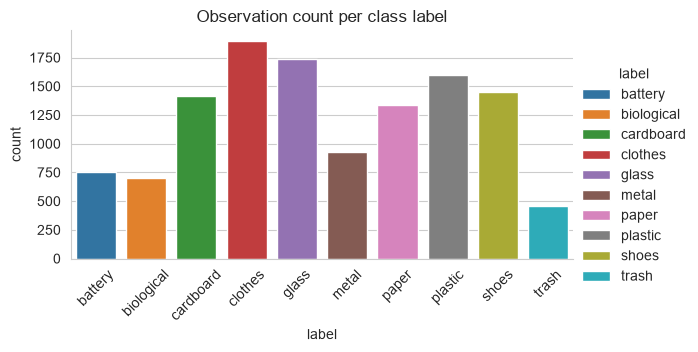

In [5]:
import seaborn as sns

sns.set_style("whitegrid")
sns.catplot(label_counts, x="label", y="count", kind="bar", hue="label", legend=True, height=3, aspect=2)
plt.xticks(rotation=45)
plt.title("Observation count per class label")
plt.show()

In [6]:
# Split dataset into train and test
data_split = dataset.train_test_split(test_size=0.2, shuffle=True, seed=42, stratify_by_column="label")
train = data_split["train"]
test = data_split["test"]
print("Train Split:\n", count_observations(train))
print("\nTest Split:\n", count_observations(test))

Train Split:
         label  count
0     battery    605
1  biological    559
2   cardboard   1129
3     clothes   1513
4       glass   1389
5       metal    744
6       paper   1069
7     plastic   1278
8       shoes   1159
9       trash    362

Test Split:
         label  count
0     battery    151
1  biological    140
2   cardboard    282
3     clothes    379
4       glass    347
5       metal    186
6       paper    267
7     plastic    319
8       shoes    290
9       trash     91


In [7]:
# process images in test split
from transformers import CLIPImageProcessor
image_processor = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")

def preprocess_images(examples):
    images = examples["image"]
    inputs = image_processor(images, return_tensors="pt")
    examples["pixel_values"] = inputs["pixel_values"]
    return examples

test = test.map(preprocess_images, batched=True, remove_columns=["image"])

### Utility functions import

In [8]:
from utils import (
    evaluate_predictions,
    plot_conf_matrix,
    get_device,
    extract_image_embeddings,
    sample_few_shot_embeddings
)

In [9]:
device = get_device()
print(device)

mps


### Compute Test Image Embeddings

In [10]:
from transformers import logging as hf_logging

# reduce output when computing image embeddings
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

test_image_embeddings, test_labels = extract_image_embeddings(test, device)

## Few-Shot Classification

### Linear Probe Few-Shot

In [11]:
# ----- FEW-SHOT CONFIGURATION ------
k_values = [1, 2, 4, 8, 16, 32, 64]
n_seeds = 5
random_state = 42
logreg_max_iter = 1000

In [12]:
from sklearn.metrics import accuracy_score
from datasets.utils.logging import disable_progress_bar
disable_progress_bar()      # prevent progress output for .map() function

def run_few_shot_linear_probe(k: int, seed:int, dataset, max_iter: int = 100, scale: bool = True, device = None):
    """Train and evaluate a few-shot linear probe (logistic regression) on top of frozen embeddings.

    Samples a k-shot training set of image embeddings and labels from `dataset`,
    optionally standardizes features, fits a logistic regression classifier on
    the sampled training embeddings, and evaluates it on the global test
    embeddings/labels (`test_image_embeddings`, `test_labels`).

    Args:
        k (int): Number of examples per class to sample for the few-shot training set.
        seed (int): Random seed used for sampling and for the LogisticRegression
            classifier, ensuring reproducibility.
        dataset: Dataset (or dataset identifier) passed to `sample_few_shot_embeddings`
            to draw the k-shot support set from.
        max_iter (int, optional): Maximum number of iterations for the LogisticRegression
            solver. Defaults to 100.
        scale (bool, optional): If True, standardizes features (zero mean, unit variance)
            using `StandardScaler` fit on the training embeddings and applied to both
            train and test embeddings. Defaults to True.
        device (optional): Device (e.g. "cpu" or "cuda") passed to `sample_few_shot_embeddings`
            for computing/sampling the training embeddings. Defaults to None.

    Returns:
        tuple:
            accuracy (float): Classification accuracy on the test set.
            lr (sklearn.linear_model.LogisticRegression): The fitted logistic regression model.
            preds (np.ndarray): Predicted labels for the test set.

    Note:
        Relies on the module-level globals `test_image_embeddings` and `test_labels`
        for evaluation.
    """

    X_train, y_train = sample_few_shot_embeddings(k, seed, dataset, device)
    X_test = np.copy(test_image_embeddings)

    # Use Standardscaler
    if scale:
        from sklearn.preprocessing import StandardScaler
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train) # type: ignore
        X_test = scaler.transform(X_test)

    # Train logreg
    from sklearn.linear_model import LogisticRegression
    lr = LogisticRegression(random_state=seed, max_iter=max_iter)
    lr.fit(X_train, y_train)

    # Predict and evaluate
    preds = lr.predict(X_test)
    accuracy = accuracy_score(test_labels, preds)

    return accuracy, lr, preds

#### Run full k-shot sweep to produce results

In [ ]:
### ----- WARNING -----
# Running this cell will take long. The outcomes are stored in the repository and loaded from there in the next cell.
# To actually run the cell, flip the following variable to True.

RUN_EXPENSIVE_CELL = False

if not RUN_EXPENSIVE_CELL:
    raise Exception("Skipped on purpose — flip RUN_EXPENSIVE_CELL to True to run.")

import joblib

few_shot_results = []   # rows of {k, seed, scaled, accuracy}
trained_probes = {}     # (k, seed, scaled) -> (classifier, predictions)

for k in k_values:
    for seed_offset in range(n_seeds):
        for scale in [False, True]:
            seed = random_state + seed_offset
            accuracy, lr, preds = run_few_shot_linear_probe(
                k, seed, train, max_iter=logreg_max_iter, scale=scale, device=device
            )
            few_shot_results.append({
                "k": k,
                "seed": seed,
                "scaled": scale,
                "accuracy": accuracy
            })
            trained_probes[(k, seed, scale)] = (lr, preds)
    print(f"Runs for k={k:>2} completed.")

joblib.dump(few_shot_results, "few_shot_results.pkl")
joblib.dump(trained_probes, "trained_probes.pkl", )

['trained_probes.pkl']

In [13]:
import joblib

few_shot_results = joblib.load("few_shot_results.pkl")  # rows of {k, seed, scaled, accuracy}
trained_probes = joblib.load("trained_probes.pkl")      # (k, seed, scaled) -> (classifier, predictions)

few_shot_df = pd.DataFrame(few_shot_results)
few_shot_df.to_csv("linear_probe_results.csv")

few_shot_summary = few_shot_df.groupby(["k", "scaled"])["accuracy"].agg(["mean", "std"]).reset_index()
few_shot_summary

,k,scaled,mean,std
0,1,False,0.575693,0.046549
1,1,True,0.571452,0.047304
2,2,False,0.700408,0.027925
3,2,True,0.720799,0.028488
4,4,False,0.756036,0.026593
5,4,True,0.791191,0.027985
6,8,False,0.811990,0.017657
7,8,True,0.860033,0.006274
8,16,False,0.845677,0.012257
9,16,True,0.890375,0.006301


#### Plot Few-Shot Curve & Evaluate Best Classifier

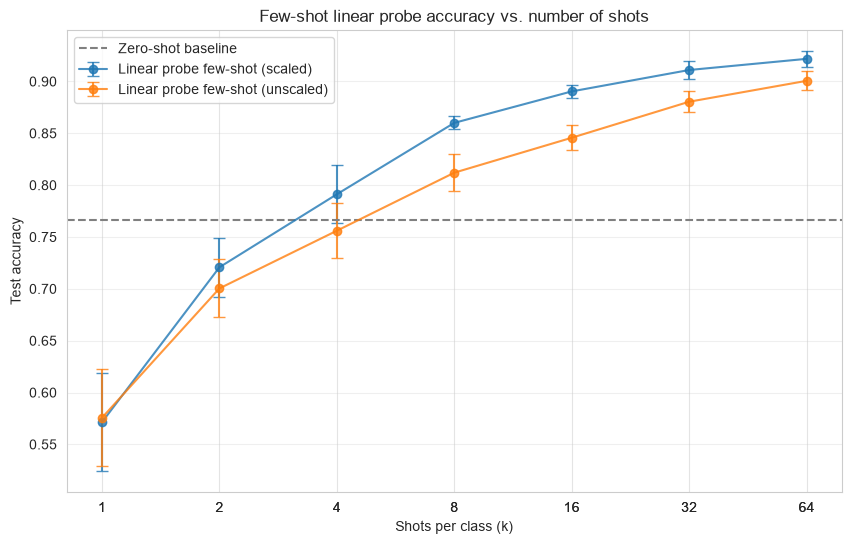

In [14]:
# Zero-Shot accuracy as baseline (best model from Zero-Shot notebook)
zero_shot_accuracy = 0.7659

# Plot Few-Shot Curve (accuracy vs. n_shots per class (k))
fig, ax = plt.subplots(figsize=(10, 6))
for scaled in [True, False]:
    df = few_shot_summary[few_shot_summary["scaled"] == scaled]
    plt.errorbar(
        df["k"],
        df["mean"],
        yerr=df["std"],
        marker = "o",
        capsize=4,
        label=f"Linear probe few-shot ({"scaled" if scaled else "unscaled"})",
        alpha = .8
    )
if zero_shot_accuracy is not None:
    plt.axhline(zero_shot_accuracy, color="gray", linestyle="--", label="Zero-shot baseline")
plt.xscale("log", base=2)
plt.xticks(few_shot_summary["k"], list(few_shot_summary["k"]))
plt.xlabel("Shots per class (k)")
plt.ylabel("Test accuracy")
plt.title("Few-shot linear probe accuracy vs. number of shots")
plt.legend()
plt.grid(alpha=.3)
plt.show()


Results:    
Accuracy:       0.9160
Precision:      0.9219
Recall:         0.9160
F1:             0.9177
              precision    recall  f1-score   support

     battery       0.95      0.97      0.96       151
  biological       0.98      0.98      0.98       140
   cardboard       0.92      0.89      0.90       282
     clothes       0.99      0.99      0.99       379
       glass       0.95      0.86      0.90       347
       metal       0.83      0.89      0.86       186
       paper       0.89      0.87      0.88       267
     plastic       0.87      0.87      0.87       319
       shoes       1.00      0.99      0.99       290
       trash       0.59      0.85      0.70        91

    accuracy                           0.92      2452
   macro avg       0.90      0.91      0.90      2452
weighted avg       0.92      0.92      0.92      2452



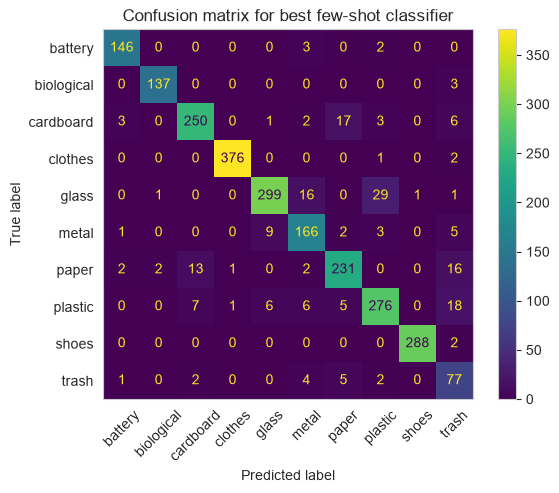

In [15]:
# identify combination of parameters (k, scaled) with highest mean accuracy
best_config_idx = few_shot_summary["mean"].argmax()
best_config = few_shot_summary.iloc[best_config_idx][["k", "scaled"]]
best_k, best_scaled = best_config.astype(int)

# extract predictions of best classifier for evaluation
_, representative_preds = trained_probes[(best_k, random_state, best_scaled)]

# Evaluate predictions
evaluate_predictions(test_labels, representative_preds, target_names=labels)
plot_conf_matrix(test_labels, representative_preds, title="Confusion matrix for best few-shot classifier", display_labels=labels)